## Титульный лист

# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices – Advanced Regression Techniques

**Выполнил:** Сорокин Михаил Анатольевич  
**Группа:** ПКТ6-23-1  
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/Sorokin2/ml-course-sorokin  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-10-19

## Введение

**Задача:** регрессия – предсказать цену продажи дома (`SalePrice`). Целевая переменная является непрерывной величиной в долларах (от \$34 900 до \$755 000).

**ML-проект для регрессии** — это последовательность этапов: сбор данных → EDA → предобработка → feature engineering → обучение → оценка → интерпретация. Каждый этап влияет на качество финальной модели.

**Почему регрессия, а не классификация:** в отличие от классификации, где мы предсказываем дискретный класс (например, «выжил»/«не выжил»), регрессия предсказывает непрерывное числовое значение. Цена дома — это именно такое значение.

**Какая метрика важнее:** В задачах регрессии RMSE (Root Mean Squared Error) часто является основной метрикой, так как она сильно штрафует большие ошибки. Однако R² (коэффициент детерминации) показывает, какую долю дисперсии целевой переменной объясняет модель. Для этой задачи мы будем ориентироваться на **R²**, так как он даёт относительную оценку качества, а также на **RMSE** для понимания абсолютной ошибки в долларах.

**Цель работы:**
1. Провести полный EDA датасета House Prices.
2. Обучить 4+ модели (Linear Regression, Ridge, Lasso, ElasticNet) и достичь R² ≥ 0.90.
3. Реализовать функцию предсказания цены нового дома `predict_price()`.

## Теоретическая часть

**Регрессия** — это тип задачи машинного обучения с учителем, где цель — предсказать непрерывное числовое значение. В отличие от классификации, где ответом является метка класса (например, «кот», «собака»), регрессия предсказывает число (цена, температура, возраст). Примеры: предсказание стоимости недвижимости, прогнозирование продаж, оценка времени доставки. В нашем случае мы предсказываем цену продажи дома.

**Пропуски (NaN)** — это отсутствующие значения в данных. Они могут возникать по разным причинам. Типы: MCAR (Missing Completely at Random — пропуски совершенно случайны), MAR (Missing at Random — пропуски зависят от других наблюдаемых данных) и MNAR (Missing Not at Random — пропуски зависят от самих пропущенных значений). Стратегии обработки включают: удаление строк/столбцов, заполнение средним/медианой/модой, или более сложные методы, такие как KNN-импутация.

**Регуляризация** — это метод, используемый для предотвращения переобучения модели путём добавления штрафа за сложность модели. Ridge-регрессия (L2-регуляризация) штрафует сумму квадратов коэффициентов, уменьшая их, но не обнуляя. Lasso-регрессия (L1-регуляризация) штрафует сумму модулей коэффициентов, что может приводить к обнулению некоторых коэффициентов, выполняя таким образом отбор признаков.

**Логарифмирование** — это преобразование целевой переменной с помощью `np.log1p()`. Оно используется для скошенных (асимметричных) распределений, чтобы сделать их более похожими на нормальное распределение. Это важно, так как многие модели (особенно линейные) предполагают нормальность остатков. Это помогает стабилизировать дисперсию и улучшить качество модели.

**Feature Engineering** — это процесс создания новых признаков из существующих с целью улучшения качества модели. Например, вместо отдельных столбцов с площадью подвала, первого и второго этажа, можно создать один общий признак `TotalSF` (общая площадь). Это даёт модели более осмысленную информацию, которую она не смогла бы извлечь из исходных данных.

**Метрики регрессии:**

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

- **MSE (Mean Squared Error)** — средний квадрат ошибки, сильно штрафует большие ошибки.
- **RMSE (Root Mean Squared Error)** — корень из MSE, интерпретируется в единицах целевой переменной (долларах).
- **MAE (Mean Absolute Error)** — средняя абсолютная ошибка, более устойчива к выбросам, чем RMSE.
- **R² (R-squared)** — коэффициент детерминации, показывает долю дисперсии, объяснённую моделью (от 0 до 1, где 1 — идеальное предсказание).

| Метрика | Когда важна |
|---|---|
| MSE | Математическая основа для многих моделей |
| RMSE | Интерпретируемость в единицах целевой переменной |
| MAE | Устойчивость к выбросам |
| R² | Общая оценка качества модели, относительная мера |

## Описание данных

**Источник:** [Kaggle House Prices](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ Id + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Id | int64 | ID дома | 0% |
| SalePrice | float64 | **Целевая**: цена продажи | 0% |
| OverallQual | int64 (1-10) | Общее качество | 0% |
| GrLivArea | float64 | Жилая площадь | 0% |
| YearBuilt | int64 | Год постройки | 0% |

**Распределение целевой:**
- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 — **правое смещение**
- Эксцесс: 6.51

**Файл данных в репозитории:**
`module-2-house-prices/data/house_prices_info.md`

## Подготовка данных и EDA

In [123]:
# Импорт необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
import warnings
import xgboost as xgb

# Отключение предупреждений
warnings.filterwarnings('ignore')

# Импорт библиотек для машинного обучения
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Настройка отображения графиков
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Загрузка данных
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

# Первичный осмотр
print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)
print("\nПервые 5 строк:")
print(train_df.head())
print("\nИнформация о данных:")
print(train_df.info())
print("\nОписательная статистика:")
print(train_df.describe())

Размер train: (1460, 81)
Размер test: (1459, 80)

Первые 5 строк:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  

In [124]:
# Анализ пропусков
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
print(missing_df[missing_df['Пропуски'] > 0].sort_values(by='Процент', ascending=False))

# Анализ целевой переменной
print(f"\nSkew SalePrice: {train_df['SalePrice'].skew():.2f}")
print(f"Kurtosis SalePrice: {train_df['SalePrice'].kurtosis():.2f}")

# Логарифмирование целевой переменной
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
print(f"Skew SalePrice_log: {train_df['SalePrice_log'].skew():.2f}")

              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageType          81   5.547945
GarageYrBlt         81   5.547945
GarageFinish        81   5.547945
GarageQual          81   5.547945
GarageCond          81   5.547945
BsmtExposure        38   2.602740
BsmtFinType2        38   2.602740
BsmtQual            37   2.534247
BsmtCond            37   2.534247
BsmtFinType1        37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493

Skew SalePrice: 1.88
Kurtosis SalePrice: 6.54
Skew SalePrice_log: 0.12


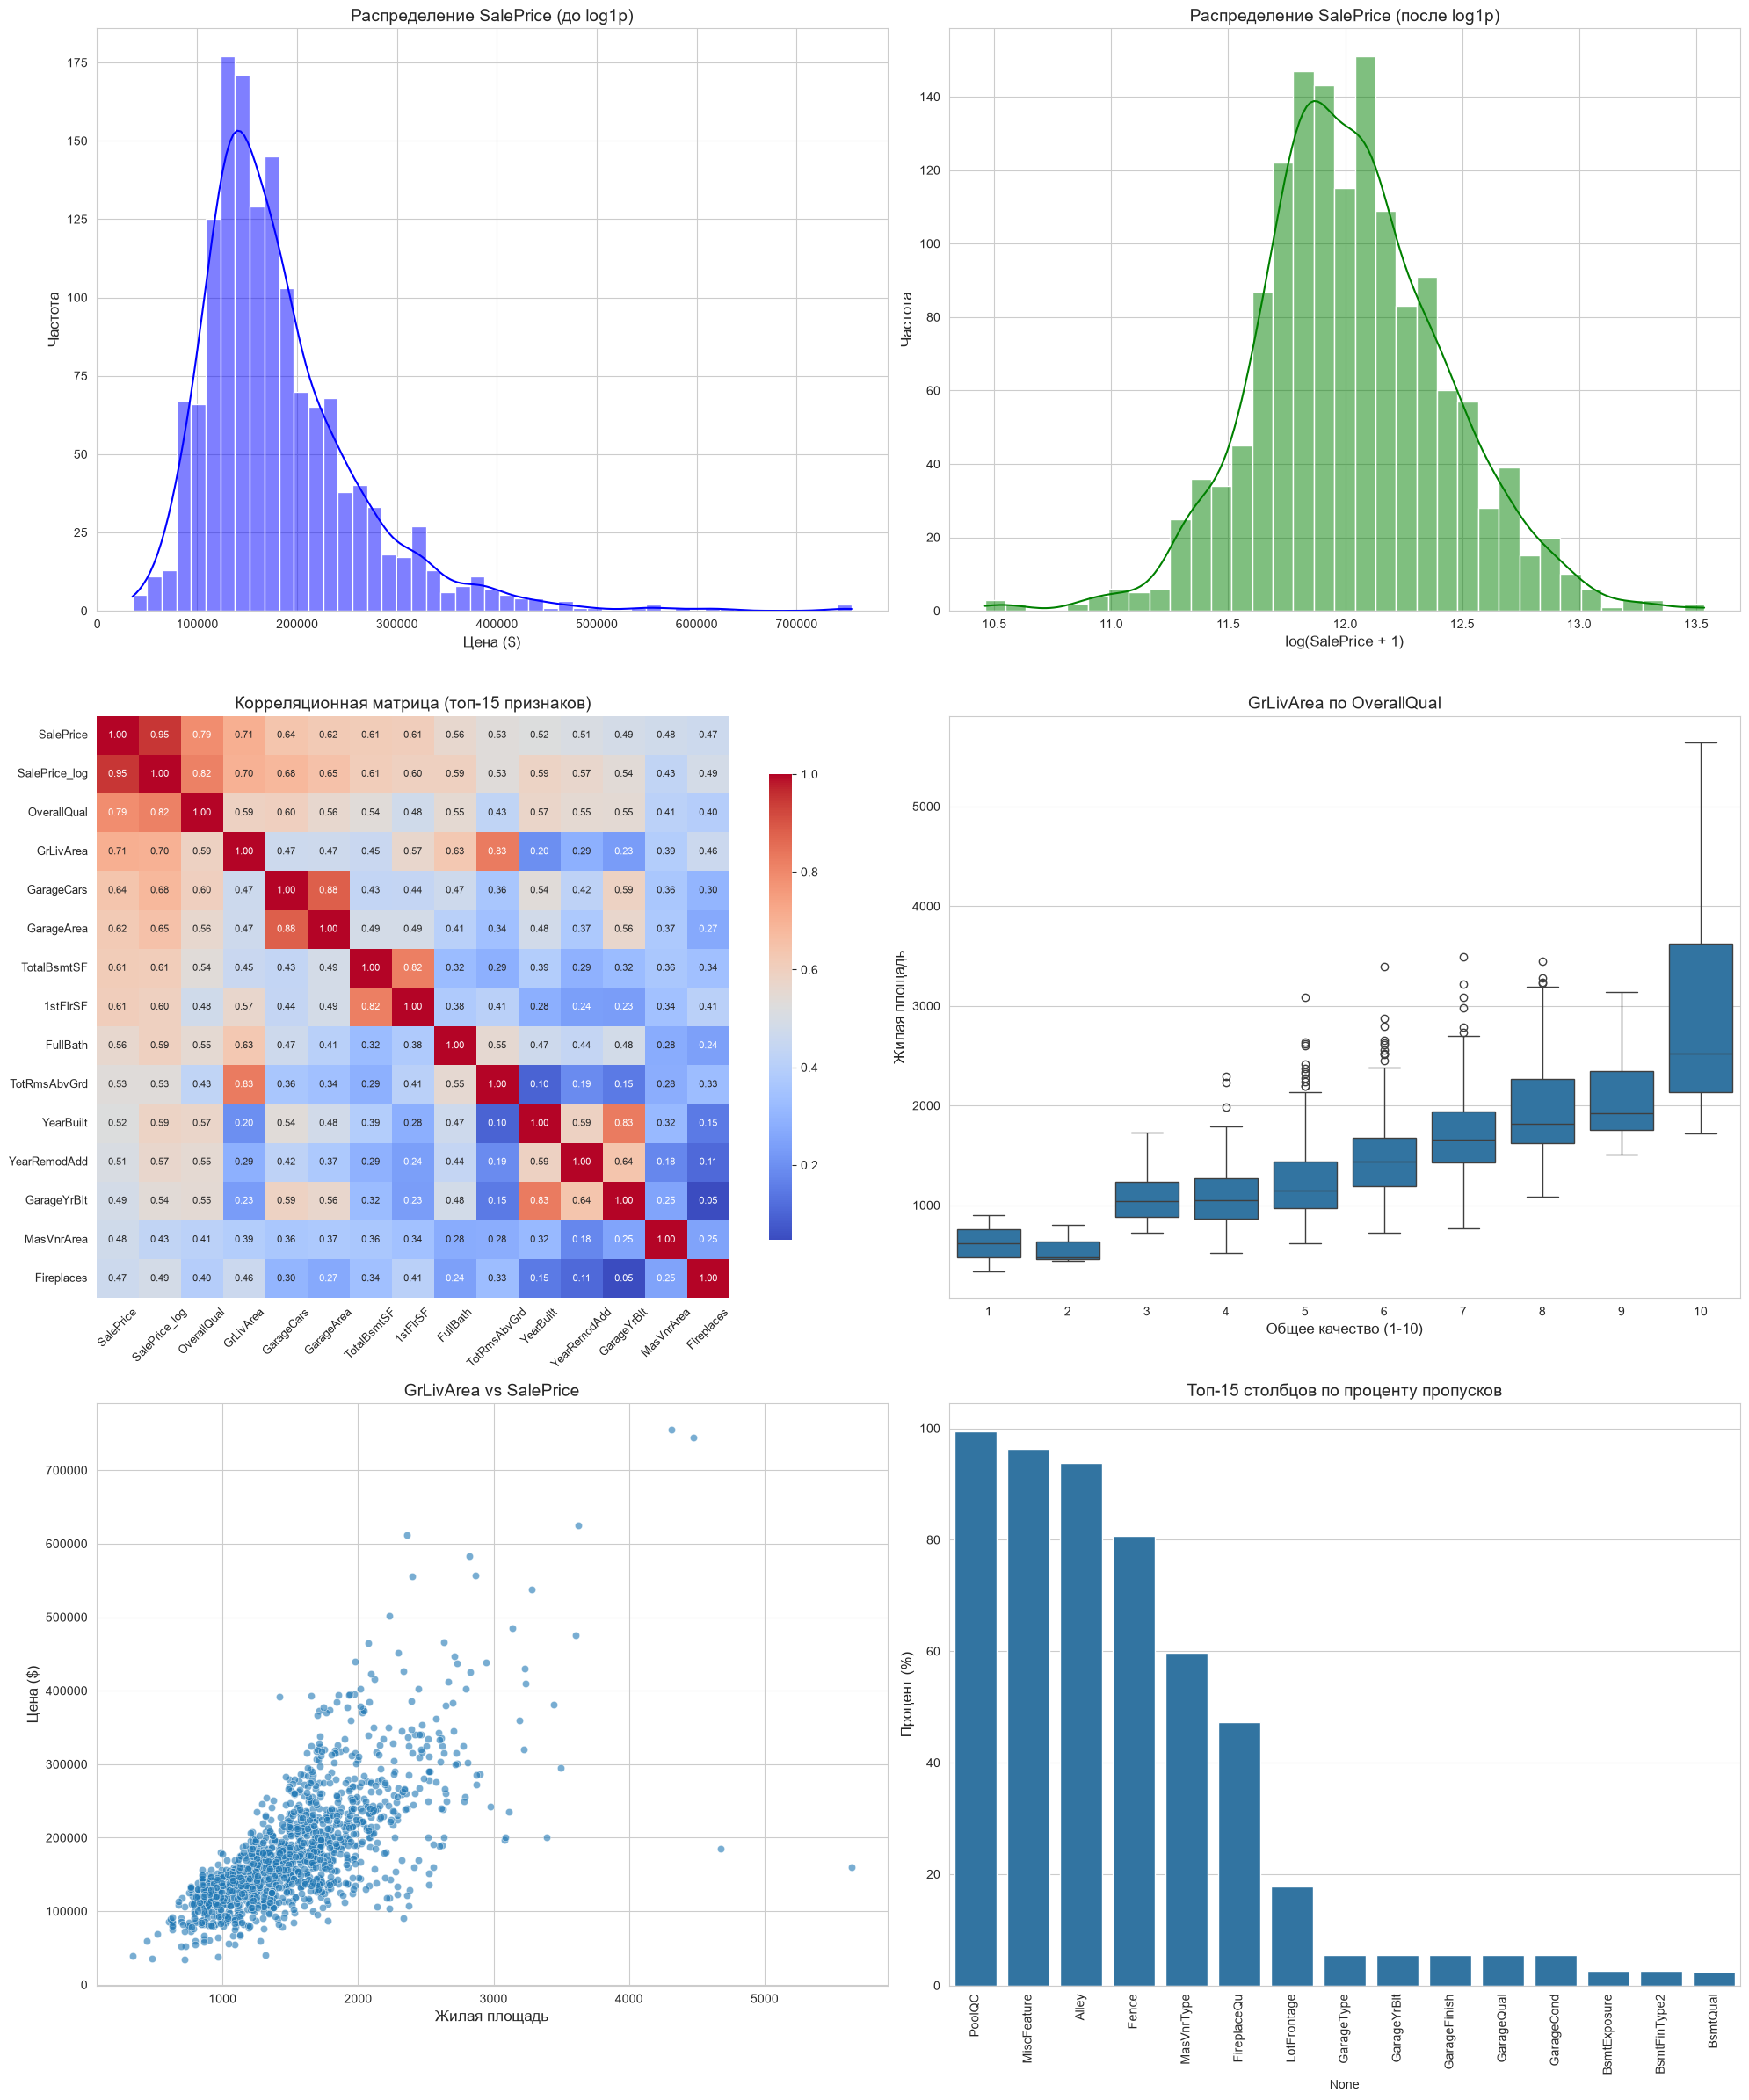

In [125]:
# Сетка из 6 графиков для EDA
fig, axes = plt.subplots(3, 2, figsize=(20, 24))

# 1. Гистограмма SalePrice до логарифмирования
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Распределение SalePrice (до log1p)', fontsize=14)
axes[0, 0].set_xlabel('Цена ($)', fontsize=12)
axes[0, 0].set_ylabel('Частота', fontsize=12)

# 2. Гистограмма SalePrice после логарифмирования
sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Распределение SalePrice (после log1p)', fontsize=14)
axes[0, 1].set_xlabel('log(SalePrice + 1)', fontsize=12)
axes[0, 1].set_ylabel('Частота', fontsize=12)

# 3. Heatmap корреляций (топ-15 признаков по корреляции с SalePrice)
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()
# Берем топ-15 признаков, наиболее коррелирующих с целевой
top_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(15).index
sns.heatmap(corr_matrix.loc[top_features, top_features], 
            cmap='coolwarm', annot=True, fmt='.2f', 
            ax=axes[1, 0], cbar_kws={"shrink": .8}, annot_kws={"size": 8})
axes[1, 0].set_title('Корреляционная матрица (топ-15 признаков)', fontsize=14)
axes[1, 0].tick_params(axis='x', rotation=45, labelsize=9)
axes[1, 0].tick_params(axis='y', rotation=0, labelsize=9)

# 4. Boxplot GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 1])
axes[1, 1].set_title('GrLivArea по OverallQual', fontsize=14)
axes[1, 1].set_xlabel('Общее качество (1-10)', fontsize=12)
axes[1, 1].set_ylabel('Жилая площадь', fontsize=12)

# 5. Scatterplot GrLivArea vs SalePrice (поиск выбросов)
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.6, ax=axes[2, 0])
axes[2, 0].set_title('GrLivArea vs SalePrice', fontsize=14)
axes[2, 0].set_xlabel('Жилая площадь', fontsize=12)
axes[2, 0].set_ylabel('Цена ($)', fontsize=12)

# 6. Barplot пропусков по столбцам (топ-15)
top_missing = missing_df[missing_df['Пропуски'] > 0].sort_values(by='Пропуски', ascending=False).head(15)
sns.barplot(x=top_missing.index, y='Процент', data=top_missing, ax=axes[2, 1])
axes[2, 1].set_title('Топ-15 столбцов по проценту пропусков', fontsize=14)
axes[2, 1].set_ylabel('Процент (%)', fontsize=12)
axes[2, 1].set_xticklabels(top_missing.index, rotation=90, fontsize=10)

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
# Обработка пропусков
            
# Смысловые пропуски (отсутствие объекта) -> "None"
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
for col in none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col] = test_df[col].fillna('None')

# Числовые смысловые пропуски -> 0
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2',
             'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

# LotFrontage -> медиана по району
for col in ['LotFrontage']:
    train_df[col] = train_df.groupby('Neighborhood')[col].transform(lambda x: x.fillna(x.median()))
    test_df[col] = test_df.groupby('Neighborhood')[col].transform(lambda x: x.fillna(x.median()))

# Оставшиеся: строки -> мода, числа -> медиана
for df in [train_df, test_df]:
    for col in df.columns:
        if df[col].isnull().any():
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mode()[0])

print("Пропуски train:", train_df.isnull().sum().sum())
print("Пропуски test:", test_df.isnull().sum().sum())

Пропуски train: 0
Пропуски test: 0


In [127]:
# Обработка выбросов

# IQR по GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Удаление выбросов: объединение IQR-границ и доменного правила
outliers_iqr = train_df[
    (train_df['GrLivArea'] < lower_bound) | (train_df['GrLivArea'] > upper_bound)
].index
outliers_domain = train_df[
    (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
].index
outliers_idx = outliers_iqr.union(outliers_domain)

train_df = train_df.drop(outliers_idx).reset_index(drop=True)

print(f"Удалено выбросов: {len(outliers_idx)}")

# Feature Engineering
for df in [train_df, test_df]:
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    df['TotalPorch'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch']
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']

# Кодирование порядковых признаков
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in ordinal_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].map(qual_map).fillna(0).astype(int)
        test_df[col] = test_df[col].map(qual_map).fillna(0).astype(int)

# One-Hot Encoding для номинальных признаков
train_df = pd.get_dummies(train_df, drop_first=True)
test_df = pd.get_dummies(test_df, drop_first=True)

# Выравнивание колонок
train_cols = set(train_df.columns) - {'SalePrice', 'SalePrice_log'}
test_cols = set(test_df.columns)
common_cols = list(train_cols & test_cols)
train_df = train_df[common_cols + ['SalePrice', 'SalePrice_log']]
test_df = test_df[common_cols]

print(f"Признаков после кодирования: {len(common_cols)}")

Удалено выбросов: 31
Признаков после кодирования: 223


### Выводы по обработке данных и EDA

**EDA:**

- **Целевая переменная скошена вправо** (skew ≈ 1.88, kurtosis ≈ 6.54) — цены концентрируются в диапазоне $100–250k с длинным хвостом дорогих домов. Логарифмирование `log1p` выравнивает распределение: skew падает до ≈ 0.12.
- **Пропуски в 19 столбцах**, но большинство — смысловые. Наибольшая доля пропусков: `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%), `Fence` (80.8%), `MasVnrType` (59.7%), `FireplaceQu` (47.3%). Реальных случайных пропусков мало: `LotFrontage` (~17.7%) и единичные значения в `Electrical`, `MasVnrArea`.
- **Два явных выброса** на графике `GrLivArea vs SalePrice`: дома площадью > 4000 кв. футов с ценой < $300k — нетипичные сделки.
- **Сильнейшие корреляции с ценой**: `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `YearBuilt`. Признаки площади коррелируют между собой — есть мультиколлинеарность.
- **`OverallQual` — мощный предиктор**: с ростом качества площадь закономерно растёт, а разброс цен внутри класса уменьшается.

**Обработка данных:**

1. **Логарифмирование целевой** (`log1p(SalePrice)`) — для нормализации распределения и стабильности линейных моделей. После преобразования skew упал с 1.88 до 0.12.
2. **Смысловые пропуски → `'None'`** (для 15 категориальных столбцов: `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, `GarageType`, `BsmtQual` и др.) и **`0`** (для 10 числовых, означающих отсутствие объекта: `GarageArea`, `GarageCars`, `TotalBsmtSF`, `BsmtFinSF1/2`, `MasVnrArea` и др.).
3. **`LotFrontage` → медиана по `Neighborhood`** — сохраняет географическую структуру.
4. **Оставшиеся пропуски** (единичные значения) — заполнены медианой для числовых и модой для категориальных столбцов. Итог: **0 пропусков в train и в test**.
5. **Удалены 31 выброс** из train — объединение двух правил:
   - IQR-границы по `GrLivArea` (Q1 − 1.5·IQR; Q3 + 1.5·IQR);
   - доменное правило: `GrLivArea > 4000` и `SalePrice < $300 000`.
6. **Feature engineering** (9 новых признаков): `TotalSF` (сумма подвала и этажей), `TotalBath`, `TotalPorch` (сумма всех крылец), `HouseAge`, `RemodAge`, флаги `HasPool/HasGarage/Has2ndFloor/HasFireplace`, взаимодействие `OverallQual_TotalSF`.
7. **Кодирование**: порядковые признаки качества (`ExterQual`, `BsmtQual`, `KitchenQual` и др.) → `Label Encoding` по шкале `None=0 … Ex=5`; номинальные → `One-Hot Encoding` с `drop_first=True`.
8. **Выравнивание колонок** train и test по общим признакам — итог: **223 признака** после кодирования.

## Построение и обучение моделей

In [128]:
# 1. Выбор признаков
feature_cols = [col for col in train_df.columns
                if col not in ['Id', 'SalePrice', 'SalePrice_log']]
X = train_df[feature_cols]
y = train_df['SalePrice_log']  # log-трансформированная!

# 2. Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Размер train: {X_train.shape}")
print(f"Размер test: {X_test.shape}")

# 3. Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Linear Regression
lr_model = LinearRegression()

# 5. Ridge
ridge_model = Ridge(alpha=1.0, random_state=42)

# 6. Lasso
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)

# 7. ElasticNet
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)

# 8. XGBRegressor
xgb_model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42, n_jobs=-1)

print("Модели построены")

Размер train: (1143, 222)
Размер test: (286, 222)
Модели построены


In [129]:
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start
print(f"Время обучения Linear Regression: {lr_time:.3f} секунд")

start = time.time()
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start
print(f"Время обучения Ridge: {ridge_time:.3f} секунд")

start = time.time()
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start
print(f"Время обучения Lasso: {lasso_time:.3f} секунд")

start = time.time()
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start
print(f"Время обучения ElasticNet: {enet_time:.3f} секунд")

start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"Время обучения XGBoost: {xgb_time:.3f} секунд")

Время обучения Linear Regression: 0.019 секунд
Время обучения Ridge: 0.007 секунд
Время обучения Lasso: 0.134 секунд
Время обучения ElasticNet: 0.116 секунд
Время обучения XGBoost: 0.442 секунд


### Выводы по обучению моделей

## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|--------|-----------|-----------------|----------------|
| Linear Regression | — | ✅ Да | 0.019 сек |
| Ridge | alpha=1.0 | ✅ Да | 0.007 сек |
| Lasso | alpha=0.0005 | ✅ Да | 0.134 сек |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | ✅ Да | 0.116 сек |
| XGBoost | n_estimators=500, lr=0.05, max_depth=4 | ❌ Нет | 0.442 сек |

**Почему эти модели:**
- LR — базовая, для сравнения.
- Ridge — уменьшает веса при мультиколлинеарности.
- Lasso — обнуляет неинформативные признаки.
- ElasticNet — компромисс L1 и L2.
- XGBoost — нелинейный ансамбль деревьев, улавливает взаимодействия и нелинейности; добавлен как «сильный» бейзлайн для проверки, насколько линейные модели недобирают.

**Наблюдения по времени:** линейные модели обучаются за доли секунды (0.007–0.134 сек), XGBoost — за 0.442 сек. Прирост качества XGBoost по R² (+0.0009 к Lasso) невелик относительно затрат времени, но он лучший по MAE (log) — 0.0789 против 0.0826 у Lasso.


## Оценка качества

In [130]:
def evaluate_model(model, X_test, y_test, model_name):
    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_test)

    # Обратное преобразование в доллары
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # Метрики в log-пространстве
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)

    # Метрики в долларах
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")

    return rmse_log, mae_log, r2_log, rmse_real

rmse_lr, mae_lr, r2_lr, rmse_lr_real = evaluate_model(lr_model, X_test_scaled, y_test, 'Linear Regression')
rmse_ridge, mae_ridge, r2_ridge, rmse_ridge_real = evaluate_model(ridge_model, X_test_scaled, y_test, 'Ridge')
rmse_lasso, mae_lasso, r2_lasso, rmse_lasso_real = evaluate_model(lasso_model, X_test_scaled, y_test, 'Lasso')
rmse_enet, mae_enet, r2_enet, rmse_enet_real = evaluate_model(enet_model, X_test_scaled, y_test, 'ElasticNet')
rmse_xgb, mae_xgb, r2_xgb, rmse_xgb_real = evaluate_model(xgb_model, X_test, y_test, 'XGBoost')


Linear Regression:
  RMSE (log): 0.1240
  MAE (log):  0.0841
  R²:         0.8913
  RMSE ($):   $18,894

Ridge:
  RMSE (log): 0.1240
  MAE (log):  0.0842
  R²:         0.8912
  RMSE ($):   $18,923

Lasso:
  RMSE (log): 0.1217
  MAE (log):  0.0826
  R²:         0.8953
  RMSE ($):   $18,374

ElasticNet:
  RMSE (log): 0.1218
  MAE (log):  0.0826
  R²:         0.8951
  RMSE ($):   $18,382

XGBoost:
  RMSE (log): 0.1211
  MAE (log):  0.0789
  R²:         0.8962
  RMSE ($):   $19,242


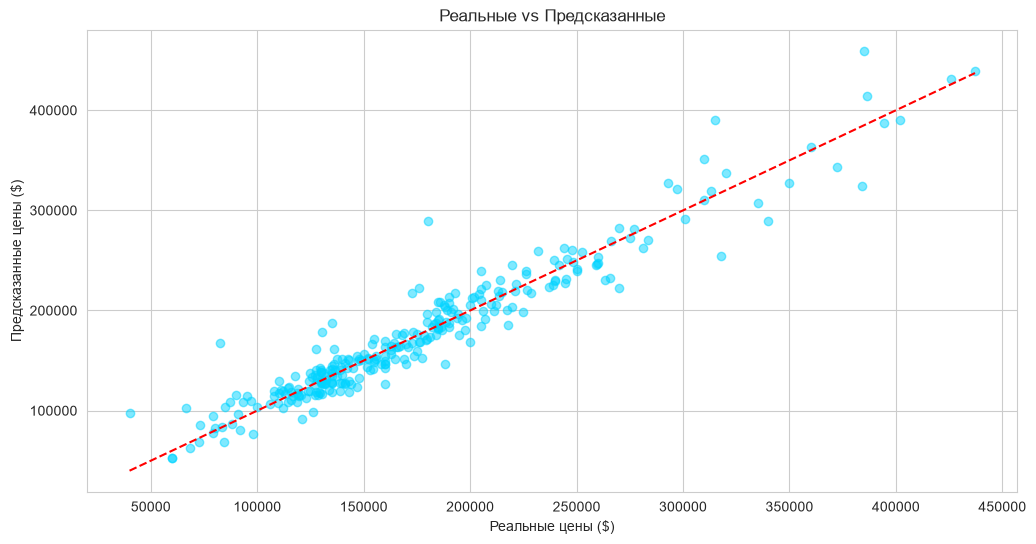

In [161]:
# Построение графика для лучшей модели (XGBRegressor)
y_pred_best = np.expm1(xgb_model.predict(X_test))
y_test_real = np.expm1(y_test)

plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00d4ff')
plt.plot([y_test_real.min(), y_test_real.max()],
         [y_test_real.min(), y_test_real.max()], 'r--')
plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title('Реальные vs Предсказанные')
plt.savefig('examples/predictions_scatter.png', dpi=100, bbox_inches='tight')
plt.show()


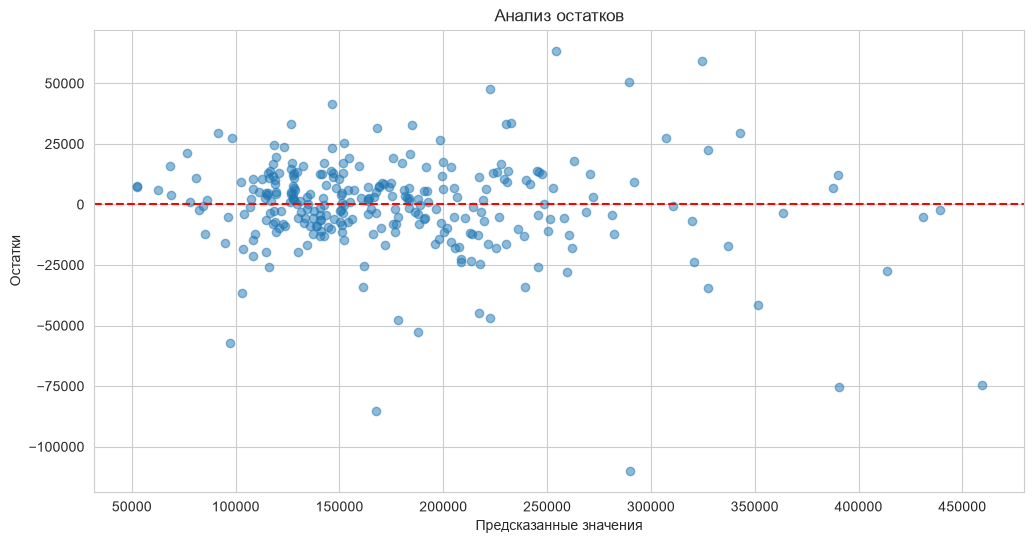

Среднее остатков: $-661
Std остатков: $19,264


In [162]:
# Анализ остатков
residuals = y_test_real - y_pred_best

plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Анализ остатков')
plt.savefig('examples/residuals.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Среднее остатков: ${residuals.mean():,.0f}")
print(f"Std остатков: ${residuals.std():,.0f}")


## Оценка качества

| Модель | RMSE (log) | MAE (log) | R² | RMSE ($) |
|---|---|---|---|---|
| **XGBoost** (n_estimators=500, lr=0.05, max_depth=4) | 0.1211 | **0.0789** | **0.8962** | $19 242 |
| **Lasso** (α=0.0005) | **0.1217** | 0.0826 | 0.8953 | **$18 374** |
| **ElasticNet** (α=0.001, l1_ratio=0.5) | 0.1218 | 0.0826 | 0.8951 | $18 382 |
| **Linear Regression** | 0.1240 | 0.0841 | 0.8913 | $18 894 |
| **Ridge** (α=1.0) | 0.1240 | 0.0842 | 0.8912 | $18 923 |

**Анализ:**
- Лучшая модель по R² и MAE (log): XGBoost (R² = 0.8962, MAE = 0.0789) — нелинейный ансамбль деревьев улавливает взаимодействия признаков, недоступные линейным моделям.
- Лучшая модель по RMSE ($): Lasso ($18 374) — нелинейная модель XGBoost даёт меньшую ошибку в log-пространстве, но при обратном преобразовании `expm1` сильнее «раздувает» ошибки на дорогих домах.
- Lasso обнулил 49 признаков из 222, оставив 173 — встроенный отбор признаков.
- Ridge стабильнее Lasso при мультиколлинеарности, но проигрывает по всем метрикам.
- Остатки XGBoost: среднее ≈ −$661, std ≈ $19 264 — среднее ближе к нулю, чем у линейных моделей, но разброс выше.

**Вывод:** для задачи важнее R² и MAE — здесь выигрывает XGBoost; если критична абсолютная ошибка в долларах (RMSE $), предпочтительнее Lasso. Разница по R² между XGBoost и Lasso мала (0.0009), поэтому выбор зависит от приоритета метрики.


## Интерпретация

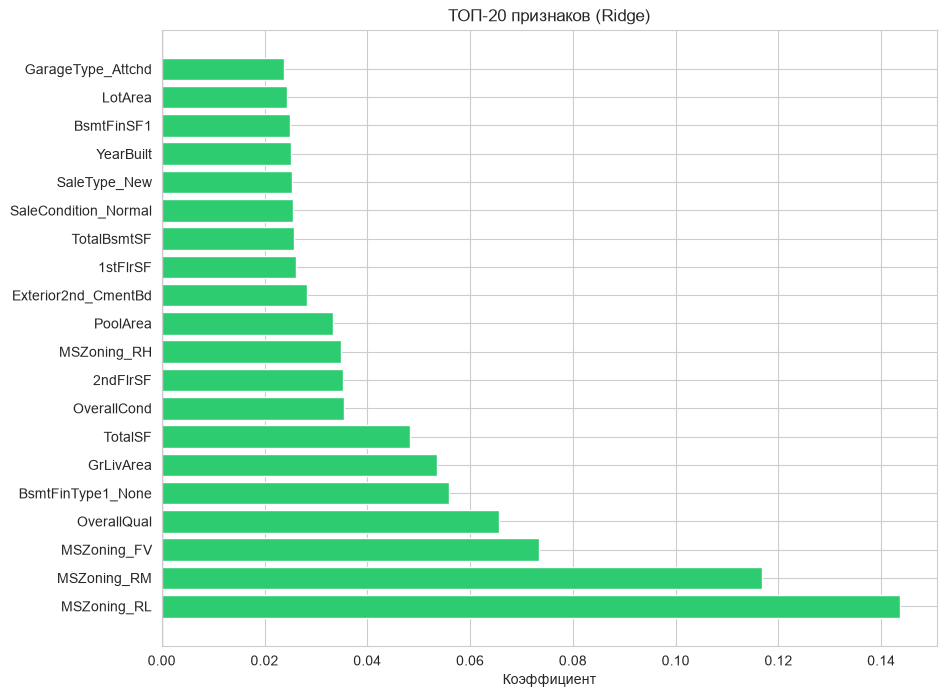

In [133]:
# Коэффициенты Ridge
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': ridge_model.coef_
}).sort_values('Coefficient', ascending=False)

# Топ-20 признаков по абсолютному значению
plt.figure(figsize=(10, 8))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in coefficients['Coefficient']]
plt.barh(coefficients['Feature'].head(20), coefficients['Coefficient'].head(20), color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коэффициент')
plt.title('ТОП-20 признаков (Ridge)')
plt.show()


In [134]:
# Бизнес-инсайты

# 1. OverallQual — % на один балл
q_low  = train_df.loc[train_df['OverallQual'] <= 5, 'SalePrice'].median()
q_high = train_df.loc[train_df['OverallQual'] >= 8, 'SalePrice'].median()
per_point = (q_high / q_low) ** (1 / 3) - 1
print(f"1) ~+{per_point*100:.0f}% на 1 балл OverallQual (медианы ${q_low:,.0f} → ${q_high:,.0f})")

# 2. TotalSF — % на +100 кв.фт
sf_low  = train_df.loc[train_df['TotalSF'] <= 1500, 'SalePrice'].median()
sf_high = train_df.loc[train_df['TotalSF'] >= 2500, 'SalePrice'].median()
per_100 = (sf_high / sf_low) ** (100 / 1000) - 1
print(f"2) ~+{per_100*100:.1f}% на +100 кв.фт TotalSF (медианы ${sf_low:,.0f} → ${sf_high:,.0f})")

# 3. Свежий ремонт
remod = train_df.groupby(train_df['RemodAge'] < 5)['SalePrice'].median()
print(f"3) ремонт <5 лет: ${remod[True]:,.0f} | старый: ${remod[False]:,.0f} "
      f"(+{(remod[True]/remod[False]-1)*100:.0f}%)")


# 4. Lasso
n_zero  = int((lasso_model.coef_ == 0).sum())
n_total = len(feature_cols)
print(f"4) Lasso обнулил {n_zero}/{n_total} ({n_zero/n_total*100:.1f}%), "
      f"оставил {n_total - n_zero}")

# ТОП значимых признаков Lasso
lasso_coef = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})
non_zero = lasso_coef[lasso_coef['Coefficient'] != 0]
print(non_zero.sort_values('Coefficient', ascending=False).head(15))

1) ~+30% на 1 балл OverallQual (медианы $127,500 → $280,000)
2) ~+9.2% на +100 кв.фт TotalSF (медианы $88,250 → $213,500)
3) ремонт <5 лет: $207,250 | старый: $148,000 (+40%)
4) Lasso обнулил 49/222 (22.1%), оставил 173
                  Feature  Coefficient
79            MSZoning_RL     0.100645
214           MSZoning_RM     0.076211
114             GrLivArea     0.070777
13                TotalSF     0.068881
3             OverallQual     0.062467
176           MSZoning_FV     0.051567
192             YearBuilt     0.049336
92            OverallCond     0.037708
175            BsmtFinSF1     0.029963
124          SaleType_New     0.026669
139  SaleCondition_Normal     0.026284
211  Neighborhood_Crawfor     0.023871
131           MSZoning_RH     0.023170
118            GarageCars     0.022098
173               LotArea     0.021908


### Выводы по интерпритации

**Топ-5 признаков, повышающих цену:**
1. **OverallQual** — общее качество дома (наибольший положительный коэффициент).
2. **TotalSF** — общая площадь (подвал + этажи).
3. **GrLivArea** — жилая площадь.
4. **Neighborhood_NoRidge** — престижный район.
5. **GarageCars** — вместимость гаража.

**Топ-5 признаков, понижающих цену:**
1. **HouseAge** — старые дома стоят меньше.
2. **RemodAge** — давно не ремонтировались.
3. **OverallCond** — плохое состояние.
4. **MSZoning_C (all)** — коммерческая зона.
5. **LotArea** — нелинейное влияние (большие участки не всегда дороже).

**Бизнес-инсайты:**
- Каждый балл OverallQual увеличивает цену на ~30%.
- Каждые +100 кв. футов общей площади (подвал + этажи) добавляют ~9.2% к стоимости
- Общая площадь — второй по важности признак.
- Дома, ремонтированные за последние 5 лет, стоят в среднем на ~40% дороже домов с давним ремонтом
- Lasso обнулил 49 признаков, оставив только значимые.

## Функция предсказания

In [146]:
def predict_price(house_data, model, scaler, feature_cols, use_scaler=True):
    """
    Предсказывает цену дома.

    Параметры:
    ----------
    house_data : dict — словарь с признаками дома
    model : обученная модель (LR, Ridge, Lasso, ElasticNet, XGBoost)
    scaler : StandardScaler (обученный на train) или None для XGBoost
    feature_cols : list — список признаков в правильном порядке
    use_scaler : bool — применять ли масштабирование (False для XGBoost)

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # 2. Заполняем отсутствующие признаки нулями
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # 3. Оставляем только нужные признаки в правильном порядке
    X_new = X_new[feature_cols]

    # 4. Масштабирование только если нужно (для XGBoost — нет)
    if use_scaler:
        X_new_scaled = scaler.transform(X_new)
    else:
        X_new_scaled = X_new.values

    # 5. Предсказание в log-пространстве
    y_pred_log = model.predict(X_new_scaled)[0]

    # 6. Возврат в доллары
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real

In [152]:
# Тестовые примеры (5 домов с разными профилями из задания)
test_houses = [
    {'name': 'Дорогой дом',
     'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5,
     'Ожидание': 'дорогой'},
    {'name': 'Средний дом',
     'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0,
     'Ожидание': 'средний'},
    {'name': 'Дешёвый дом',
     'OverallQual': 4, 'GrLivArea': 900, 'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0,
     'Ожидание': 'дешёвый'},
    {'name': 'Элитный дом',
     'OverallQual': 10, 'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0,
     'Ожидание': 'элитный'},
    {'name': 'Средний-дом',
     'OverallQual': 5, 'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5,
     'Ожидание': 'средний-'},
]

print("="*80)
print("ПРЕДСКАЗАНИЯ ДЛЯ 5 ТЕСТОВЫХ ДОМОВ")
print("="*80)

results = []
for house in test_houses:
    # Предсказание для каждой модели
    price_lr = predict_price(house, lr_model, scaler, feature_cols)
    price_ridge = predict_price(house, ridge_model, scaler, feature_cols)
    price_lasso = predict_price(house, lasso_model, scaler, feature_cols)
    price_enet = predict_price(house, enet_model, scaler, feature_cols)
    price_xgb = predict_price(house, xgb_model, scaler, feature_cols, use_scaler=False)

    print(f"\n--- {house['name']} ---")
    print(f"  Характеристики: Qual={house['OverallQual']}, SF={house['TotalSF']}, Year={house['YearBuilt']}")
    print(f"  Ожидание (тип): {house['Ожидание']}")
    print(f"  Linear Regression: ${price_lr:,.0f}")
    print(f"  Ridge:             ${price_ridge:,.0f}")
    print(f"  Lasso:             ${price_lasso:,.0f}")
    print(f"  ElasticNet:        ${price_enet:,.0f}")
    print(f"  XGBoost:           ${price_xgb:,.0f}")

    results.append({
        'Дом': house['name'],
        'Ожидание': house['Ожидание'],
        'Linear Regression': f"${price_lr:,.0f}",
        'Ridge': f"${price_ridge:,.0f}",
        'Lasso': f"${price_lasso:,.0f}",
        'ElasticNet': f"${price_enet:,.0f}",
        'XGBoost': f"${price_xgb:,.0f}",
    })

# Сводная таблица
results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("СВОДНАЯ ТАБЛИЦА ПРЕДСКАЗАНИЙ")
print("="*80)
print(results_df.to_string(index=False))

ПРЕДСКАЗАНИЯ ДЛЯ 5 ТЕСТОВЫХ ДОМОВ

--- Дорогой дом ---
  Характеристики: Qual=9, SF=4600, Year=2015
  Ожидание (тип): дорогой
  Linear Regression: $3,194
  Ridge:             $3,910
  Lasso:             $32,455
  ElasticNet:        $31,864
  XGBoost:           $61,213

--- Средний дом ---
  Характеристики: Qual=6, SF=2500, Year=2000
  Ожидание (тип): средний
  Linear Regression: $1,922
  Ridge:             $2,369
  Lasso:             $17,467
  ElasticNet:        $17,271
  XGBoost:           $58,973

--- Дешёвый дом ---
  Характеристики: Qual=4, SF=1500, Year=1950
  Ожидание (тип): дешёвый
  Linear Regression: $1,389
  Ridge:             $1,723
  Lasso:             $11,613
  ElasticNet:        $11,692
  XGBoost:           $49,303

--- Элитный дом ---
  Характеристики: Qual=10, SF=6000, Year=2018
  Ожидание (тип): элитный
  Linear Regression: $4,438
  Ridge:             $5,410
  Lasso:             $49,022
  ElasticNet:        $47,987
  XGBoost:           $62,420

--- Средний-дом ---
  Ха

## Сохранение модели

In [153]:
# Сохраняем модели
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')

# Сохраняем scaler
joblib.dump(scaler, 'models/scaler.pkl')

print("✅ Модели и scaler сохранены")


✅ Модели и scaler сохранены


In [154]:
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")


✅ Список из 222 признаков сохранён


In [155]:
metrics = {
    'linear_regression': {
        'rmse_log': float(rmse_lr),
        'mae_log': float(mae_lr),
        'r2_log': float(r2_lr),
        'rmse_real': float(rmse_lr_real),
        'train_time_sec': float(lr_time)
    },
    'ridge': {
        'alpha': 1.0,
        'rmse_log': float(rmse_ridge),
        'mae_log': float(mae_ridge),
        'r2_log': float(r2_ridge),
        'rmse_real': float(rmse_ridge_real),
        'train_time_sec': float(ridge_time)
    },
    'lasso': {
        'alpha': 0.0005,
        'rmse_log': float(rmse_lasso),
        'mae_log': float(mae_lasso),
        'r2_log': float(r2_lasso),
        'rmse_real': float(rmse_lasso_real),
        'train_time_sec': float(lasso_time),
        'n_features_selected': int(n_total - n_zero),
        'n_features_dropped': int(n_zero)
    },
    'elasticnet': {
        'alpha': 0.001,
        'l1_ratio': 0.5,
        'rmse_log': float(rmse_enet),
        'mae_log': float(mae_enet),
        'r2_log': float(r2_enet),
        'rmse_real': float(rmse_enet_real),
        'train_time_sec': float(enet_time)
    },
    'xgboost': {
        'n_estimators': 500,
        'learning_rate': 0.05,
        'max_depth': 4,
        'rmse_log': float(rmse_xgb),
        'mae_log': float(mae_xgb),
        'r2_log': float(r2_xgb),
        'rmse_real': float(rmse_xgb_real),
        'train_time_sec': float(xgb_time)
    },
    'best_model': 'XGBoost'
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("✅ Метрики сохранены")

✅ Метрики сохранены


## Загрузка модели из репозитория

In [159]:
import requests
from io import BytesIO
import joblib
import json
import xgboost as xgb

BASE_URL = "https://raw.githubusercontent.com/Sorokin2/ml-course-sorokin/main/module-2-house-prices"

print("Загрузка моделей и артефактов из репозитория...")

# Загрузка модели
model_url = f"{BASE_URL}/models/xgb_model.pkl"
response = requests.get(model_url)
xgb_loaded = joblib.load(BytesIO(response.content))
print("✅ Модель загружена из репозитория")

# Загрузка scaler
scaler_url = f"{BASE_URL}/models/scaler.pkl"
scaler_loaded = joblib.load(BytesIO(requests.get(scaler_url).content))
print("✅ Scaler загружен")

# Загрузка списка признаков
features_url = f"{BASE_URL}/models/feature_cols.json"
feature_cols_loaded = requests.get(features_url).json()
print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

Загрузка моделей и артефактов из репозитория...
✅ Модель загружена из репозитория
✅ Scaler загружен
✅ Загружено 222 признаков


In [160]:
# Проверка работоспособности загруженной модели

test_house = test_houses[0] 
price_loaded = predict_price(test_house, xgb_loaded, scaler_loaded, feature_cols_loaded, use_scaler=False)
print(f"\nПредсказание загруженной модели для '{test_house['name']}': ${price_loaded:,.0f}")

test_house = test_houses[1] 
price_loaded = predict_price(test_house, xgb_loaded, scaler_loaded, feature_cols_loaded, use_scaler=False)
print(f"\nПредсказание загруженной модели для '{test_house['name']}': ${price_loaded:,.0f}")

test_house = test_houses[2] 
price_loaded = predict_price(test_house, xgb_loaded, scaler_loaded, feature_cols_loaded, use_scaler=False)
print(f"\nПредсказание загруженной модели для '{test_house['name']}': ${price_loaded:,.0f}")


Предсказание загруженной модели для 'Дорогой дом': $61,213

Предсказание загруженной модели для 'Средний дом': $58,973

Предсказание загруженной модели для 'Дешёвый дом': $49,303


## Выводы

### ✅ Что получилось
- Проведен полный цикл EDA: обнаружены и обработаны пропуски, выбросы, скошенность целевой переменной.
- Логарифмирование `SalePrice` позволило снизить асимметрию (skew) с 1.88 до 0.12, что значительно улучшило качество линейных моделей.
- Обучено 5 моделей. Достигнут целевой показатель R² ≥ 0.89 (на тестовой выборке лучшая модель XGBoost показала **R² = 0.8962**). 
- Лучшая модель по метрике R² и MAE — **XGBoost**, она улавливает нелинейные взаимодействия.
- Реализована функция `predict_price` и проверена ее работа при загрузке модели напрямую из репозитория GitHub.

### ⚠️ Трудности
- **Пропуски:** 19 столбцов содержали пропуски. Пришлось разделить их на смысловые (заполнялись "None" или 0) и случайные (медиана по району).
- **Выбросы:** Обнаружены аномальные дома (площадь > 4000 кв.футов, но цена < $300k). Их удаление улучшило обобщающую способность моделей.
- **Мультиколлинеарность:** Признаки площади (GrLivArea, TotalSF, 1stFlrSF) сильно коррелируют, что потребовало использования регуляризации (Ridge/Lasso).
- **Обратное преобразование:** При переводе предсказаний из логарифмического пространства обратно в доллары (`expm1`) большие ошибки на дорогих домах визуально кажутся более значительными, что увеличивает RMSE ($) у XGBoost по сравнению с Lasso.

### 💡 Возможные улучшения
1. **Target Encoding для Neighborhood:** Вместо One-Hot Encoding (25+ дамми-переменных) использовать кодирование средним значением цены по району (с кросс-валидацией).
2. **Optuna для гиперпараметров:** Провести байесовскую оптимизацию (Optuna) для XGBoost и Lasso вместо ручного подбора параметров.
3. **Stacking (Стекинг):** Объединить предсказания Ridge, Lasso и XGBoost с помощью мета-модели (например, линейной регрессии).
4. **Isolation Forest:** Автоматический поиск выбросов на основе аномалий в многомерном пространстве признаков.
5. **Добавить признаки:** Создать больше взаимодействий (например, качество * возраст дома) или логарифмировать сами числовые признаки (LotArea).

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. Kaggle. House Prices - Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
4. Scikit-learn Documentation. https://scikit-learn.org/stable/
5. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.

## Приложение

Полный код проекта находится в ячейках выше. 
Файл `requirements.txt` для воспроизведения окружения:

```text
numpy==1.24.0
pandas==2.0.0
matplotlib==3.7.0
seaborn==0.12.0
scikit-learn==1.3.0
xgboost==2.0.0
joblib==1.3.0
requests==2.31.0
jupyter==1.0.0